# Notebook 1: Data Collection & Preparation
**Programming for AI · TMDB Movie Data Project** · Team: 25L-3001, 25L-0004 · SEED = 4

In this notebook we get the movie data and clean it so it's ready for analysis. The steps are:

1. Connect to the TMDB API and collect movie IDs for every year from 2016 to 2026
2. Download the full details (budget, revenue, cast, crew…) for each movie
3. Save the raw data with a `collected_at` timestamp, a collection log and a SHA-256 fingerprint
4. Explore the dataset and check for missing values and duplicates
5. Add about 5% artificial missing values and fill them back in, comparing three imputation methods (our **Advanced Technique #1**)

**What we're predicting:** a movie's box-office `revenue` in US dollars. Since that's a number, this is a regression problem.

**Files this notebook creates (in `data/`):**

| File | What's in it |
|---|---|
| `movie_ids.csv` | the movie IDs we collected, with year and rank |
| `raw_responses.jsonl` | the raw API responses, exactly as TMDB sent them |
| `tmdb_movies_raw.csv` | the raw table, untouched, with `collected_at` on every row |
| `collection_log.json`, `sha256_manifest.json` | our collection record and file fingerprints |
| `tmdb_movies_final.csv` | after removing duplicates and treating 0 as "unknown" |
| `tmdb_movies_model_base.csv` | only the movies whose revenue is known |
| `tmdb_movies_working_missing.csv` | a copy with ~5% of values blanked on purpose |
| `tmdb_movies_imputed.csv` | that copy after filling the gaps back in |

**To run it:** paste your TMDB token when asked (or set it as the `TMDB_TOKEN` environment variable) and choose Run All. The download takes about 10 to 20 minutes.

In [1]:
import os, json, time, hashlib, datetime as dt, warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

ROLL_NUMBERS = ['25L-3001', '25L-0004']   # team roll numbers
SEED = 4   # last four digits of the LOWEST roll number (25L-0004 -> 0004 -> 4), used for every random step
DATA_DIR = "data"
RAW_DIR = os.path.join(DATA_DIR, "raw_json")
FIG_DIR = "figures"
for d in (DATA_DIR, RAW_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

RAW_CSV = os.path.join(DATA_DIR, "tmdb_movies_raw.csv")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

print("Setup complete. Roll numbers:", ROLL_NUMBERS, "| SEED =", SEED)

Setup complete. Roll numbers: ['25L-3001', '25L-0004'] | SEED = 4


**What we did:** we loaded the libraries, wrote down our roll numbers and set `SEED = 4`, and created the `data/` and `figures/` folders.

**Why:** the project rules say the seed has to be the last four digits of our lowest roll number. That's 25L-0004, so 0004, which Python writes as 4. Every random step uses this seed, so anyone who runs the notebook again gets exactly the same results.

**What we found:** there's nothing to analyse yet. The printed line just confirms the roll numbers and the seed.

## Step 1: TMDB account and API key
1. Make a free account on themoviedb.org and verify your email.
2. Go to **Settings → API** and request a developer key (choose personal or educational use).
3. Copy the long **API Read Access Token** (it starts with `eyJ`), not the short API key.
4. Never type the token directly into the notebook. If you do, it gets saved in the file and anyone who sees the notebook could use it. We read it from an environment variable or ask for it when the notebook runs.

TMDB asks users to credit them (*"This product uses the TMDB API but is not endorsed or certified by TMDB"*) and limits how fast we can send requests. Our code waits a little between calls and tries again if it gets a "too many requests" error.

In [2]:
from getpass import getpass

TOKEN = os.environ.get("TMDB_TOKEN") or getpass("Paste your TMDB API Read Access Token: ")
BASE = "https://api.themoviedb.org/3"

session = requests.Session()
session.headers.update({"Authorization": f"Bearer {TOKEN}", "accept": "application/json"})

REQUEST_COUNT = 0

def tmdb_get(path, params=None, retries=6):
    """GET wrapper: retries on 429 (rate limit) and 5xx with back-off. Counts every HTTP request."""
    global REQUEST_COUNT
    for attempt in range(retries):
        REQUEST_COUNT += 1
        r = session.get(f"{BASE}{path}", params=params, timeout=30)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 429:
            time.sleep(int(r.headers.get("Retry-After", 2 ** attempt)))
            continue
        if r.status_code >= 500:
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
    raise RuntimeError(f"Failed after {retries} retries: {path}")

cfg = tmdb_get("/configuration")          # cheap call to prove the credentials work
print("Authentication OK. Image base URL:", cfg["images"]["base_url"])

Paste your TMDB API Read Access Token:  ········


Authentication OK. Image base URL: http://image.tmdb.org/t/p/


**What we did:** we read the token safely, set up a connection to TMDB, and wrote a small helper function `tmdb_get()` that sends a request and simply tries again if TMDB is busy (error 429) or has a server problem (5xx). It also counts every request, because the collection log needs that number. A quick call to `/configuration` checks that the token works.

**Why:** we send more than a thousand requests. Without retrying, one small network hiccup could crash the whole download.

**What we found:** "Authentication OK" means the token was accepted. (A 401 error here would usually mean the short API key was pasted instead of the long token.)

## Steps 2 & 3: Collecting movie IDs year by year
TMDB's Discover endpoint lets us ask for movies released between two dates, sorted however we like. These are the choices we made:

| Choice | What we used | Why |
|---|---|---|
| Endpoint | `/discover/movie` | It's the one that supports date filters and sorting |
| Dates | 1 Jan to 31 Dec, one year at a time | The brief asks for one calendar year per query |
| Sort | `vote_count.desc` (most-voted first) | Movies with lots of votes nearly always have budget, revenue and credits filled in. Sorting by popularity changes every day, so it isn't reproducible |
| Page size | 20 movies per page (fixed by TMDB) | So about 5 pages per year for 100 movies |
| How many | 100 unique movies per year | About 1,100 movies in total |
| Adult films | excluded | Not relevant to the project |
| Duplicates | a `seen` set of IDs | The same movie is never added twice |

**Limitation to keep in mind:** sorting by votes favours well-known films, so lesser-known movies are under-represented. Discover can't sort by budget, so the dataset still covers a wide range of budgets.

In [3]:
START_YEAR, END_YEAR = 2016, 2026
TARGET_PER_YEAR = 100
SORT_BY = "vote_count.desc"
MAX_PAGES = 500                      # TMDB hard limit on pagination

collection_started = dt.datetime.now().isoformat(timespec="seconds")
seen, id_records, per_year_log = set(), [], []

for year in range(START_YEAR, END_YEAR + 1):
    collected, page, pages_fetched = [], 1, 0
    total_pages = total_results = None
    while len(collected) < TARGET_PER_YEAR:
        params = {
            "primary_release_date.gte": f"{year}-01-01",
            "primary_release_date.lte": f"{year}-12-31",
            "sort_by": SORT_BY, "include_adult": "false",
            "language": "en-US", "page": page,
        }
        data = tmdb_get("/discover/movie", params)
        total_pages, total_results = data["total_pages"], data["total_results"]
        pages_fetched += 1
        for m in data["results"]:
            if m["id"] not in seen and len(collected) < TARGET_PER_YEAR:
                seen.add(m["id"])
                collected.append(m["id"])
                id_records.append({"id": m["id"], "year": year, "discover_rank": len(collected),
                                   "discover_page": page, "vote_count_at_discovery": m.get("vote_count")})
        if page >= min(total_pages, MAX_PAGES) or not data["results"]:
            break
        page += 1
        time.sleep(0.05)
    per_year_log.append({"year": year, "api_total_results": total_results, "api_total_pages": total_pages,
                         "pages_fetched": pages_fetched, "ids_collected": len(collected)})
    print(f"{year}: collected {len(collected):>3} IDs  (API reports {total_results} results / {total_pages} pages; fetched {pages_fetched} pages)")

ids_df = pd.DataFrame(id_records)
ids_df.to_csv(os.path.join(DATA_DIR, "movie_ids.csv"), index=False)
all_ids = ids_df["id"].tolist()
print("\nTotal unique IDs:", len(all_ids), "| duplicates in list:", len(all_ids) - len(set(all_ids)))


2016: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2017: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2018: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2019: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2020: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2021: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2022: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2023: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2024: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2025: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)
2026: collected 100 IDs  (API reports 20001 results / 1001 pages; fetched 5 pages)

Total unique IDs: 1100 | duplicates in list: 0


**What we did:** for each year from 2016 to 2026, we asked Discover for movies sorted by vote count and went through the pages until we had 100 new IDs. Each ID was saved to `movie_ids.csv` with its year, its rank and the page it came from.

**Why:** Discover is the only way to filter by release date. Keeping track of IDs we've already seen makes sure no movie appears twice.

**What we found:** every year reached the full 100 movies, including 2026, because TMDB reports over 20,001 results for each year. That gives **1,100 unique IDs with 0 duplicates**. Each year needed 5 pages of 20 results.

## Step 4: Downloading each movie's details and credits
For every ID we call `/movie/{id}?append_to_response=credits`. One request gives us both the details (budget, revenue, runtime, genres, companies, countries, languages) and the cast and crew. Each response is saved as its own JSON file, so if the download stops halfway, running it again picks up where it left off.

In [4]:
failed = []
t0 = time.time()
for i, mid in enumerate(all_ids, 1):
    fp = os.path.join(RAW_DIR, f"{mid}.json")
    if os.path.exists(fp):
        with open(fp, encoding="utf-8") as f:
            if "_collected_at" in json.load(f):
                continue          # cached and already time-stamped
    try:
        d = tmdb_get(f"/movie/{mid}", {"append_to_response": "credits", "language": "en-US"})
        d["_collected_at"] = dt.datetime.now().isoformat(timespec="seconds")   # collection timestamp for this row
        with open(fp, "w", encoding="utf-8") as f:
            json.dump(d, f, ensure_ascii=False)
    except Exception as e:
        failed.append((mid, str(e)))
    if i % 100 == 0:
        print(f"{i}/{len(all_ids)} done ({time.time()-t0:.0f}s)")
    time.sleep(0.03)

print("Failed IDs:", failed if failed else "none")

# combine all raw responses into one JSONL file (raw-data copy for reproducibility)
raw_jsonl = os.path.join(DATA_DIR, "raw_responses.jsonl")
n_written = 0
with open(raw_jsonl, "w", encoding="utf-8") as out:
    for mid in all_ids:
        fp = os.path.join(RAW_DIR, f"{mid}.json")
        if os.path.exists(fp):
            out.write(json.dumps(json.load(open(fp, encoding="utf-8")), ensure_ascii=False) + "\n")
            n_written += 1
print("Raw responses saved:", n_written)


Failed IDs: none
Raw responses saved: 1100


**What we did:** we downloaded the details and credits for every ID, added the time each movie was downloaded (`_collected_at`), saved each response as a JSON file, and joined them all into `raw_responses.jsonl`.

**Why:** Discover only returns basic information, with no budget, revenue or credits. Saving every response means we can rebuild the table later without calling the API again. The timestamp becomes our `collected_at` column, which the rules require.

**What we found:** no downloads failed, and all 1,100 responses were saved.

In [5]:
def names(lst, key="name"):
    return "|".join(x[key] for x in lst) if lst else None

def build_row(d):
    credits = d.get("credits") or {}
    crew, cast = credits.get("crew") or [], credits.get("cast") or []
    genres, comps = d.get("genres") or [], d.get("production_companies") or []
    countries, langs = d.get("production_countries") or [], d.get("spoken_languages") or []
    coll = d.get("belongs_to_collection")
    director = next((p["name"] for p in crew if p.get("job") == "Director"), None)
    rd = d.get("release_date") or None
    return {
        "id": d["id"], "imdb_id": d.get("imdb_id"),
        "title": d.get("title"), "original_title": d.get("original_title"),
        "release_date": rd, "status": d.get("status"),
        "original_language": d.get("original_language"),
        "budget": d.get("budget"), "revenue": d.get("revenue"), "runtime": d.get("runtime"),
        "popularity": d.get("popularity"), "vote_average": d.get("vote_average"), "vote_count": d.get("vote_count"),
        "adult": d.get("adult"), "video": d.get("video"),
        "has_homepage": bool(d.get("homepage")), "has_tagline": bool(d.get("tagline")),
        "in_collection": coll is not None, "collection_name": coll["name"] if coll else None,
        "genres": names(genres), "n_genres": len(genres), "primary_genre": genres[0]["name"] if genres else None,
        "production_companies": names(comps), "n_companies": len(comps),
        "primary_company": comps[0]["name"] if comps else None,
        "production_countries": names(countries), "n_countries": len(countries),
        "primary_country": countries[0]["name"] if countries else None,
        "n_spoken_languages": len(langs),
        "director": director, "top_cast": "|".join(p["name"] for p in cast[:3]) or None,
        "cast_size": len(cast), "crew_size": len(crew),
        "overview": d.get("overview") or None, "tagline": d.get("tagline") or None,
        "collected_at": d.get("_collected_at"),          # when this movie was downloaded
    }

rows = []
with open(raw_jsonl, encoding="utf-8") as f:
    for line in f:
        rows.append(build_row(json.loads(line)))
df_build = pd.DataFrame(rows)

# date-derived attributes
rd = pd.to_datetime(df_build["release_date"], errors="coerce")
df_build["release_year"] = rd.dt.year
df_build["release_month"] = rd.dt.month
df_build["release_dow"] = rd.dt.dayofweek          # 0 = Monday

assert df_build["collected_at"].notna().all(), "every row must carry a collected_at timestamp"
df_build.to_csv(RAW_CSV, index=False)
print("Saved", RAW_CSV, "| shape:", df_build.shape)
df_build.head(3)


Saved data\tmdb_movies_raw.csv | shape: (1100, 39)


,id,imdb_id,title,original_title,release_date,status,original_language,budget,revenue,runtime,popularity,vote_average,vote_count,adult,video,has_homepage,has_tagline,in_collection,collection_name,genres,n_genres,primary_genre,production_companies,n_companies,primary_company,production_countries,n_countries,primary_country,n_spoken_languages,director,top_cast,cast_size,crew_size,overview,tagline,collected_at,release_year,release_month,release_dow
0,293660,tt1431045,Deadpool,Deadpool,2016-02-09,Released,en,58000000,782837347,108,19.9940,7.626,33659,False,False,True,True,True,Deadpool Collection,Action|Adventure|Comedy,3,Action,20th Century Fox|The Donners' Company|Genre Fi...,4,20th Century Fox,United States of America,1,United States of America,1,Tim Miller,Ryan Reynolds|Morena Baccarin|Ed Skrein,52,489,The origin story of former Special Forces oper...,Feel the love.,2026-11-21T18:11:37,2016,2,1
1,271110,tt3498820,Captain America: Civil War,Captain America: Civil War,2016-04-27,Released,en,250000000,1155046416,147,22.4089,7.455,24890,False,False,True,True,True,Captain America Collection,Adventure|Action|Science Fiction,3,Adventure,Marvel Studios,1,Marvel Studios,United States of America,1,United States of America,4,Joe Russo,Chris Evans|Robert Downey Jr.|Scarlett Johansson,104,296,"Following the events of Age of Ultron, the col...",United we stand. Divided we fall.,2026-11-21T18:11:38,2016,4,2
2,284052,tt1211837,Doctor Strange,Doctor Strange,2016-10-25,Released,en,180000000,676343174,115,15.9164,7.424,24235,False,False,True,True,True,Doctor Strange Collection,Fantasy|Adventure|Action,3,Fantasy,Marvel Studios,1,Marvel Studios,United States of America,1,United States of America,1,Scott Derrickson,Benedict Cumberbatch|Chiwetel Ejiofor|Rachel M...,44,253,"After his career is destroyed, a brilliant but...",The impossibilities are endless.,2026-11-21T18:11:38,2016,10,1


**What we did:** we turned the nested JSON into a flat table with one row per movie:
- lists such as genres, companies, countries and top-3 cast became text joined with `|`;
- we counted things (number of genres, companies, cast and crew) and picked out the first genre, company and country, plus the director;
- we added date parts (year, month, weekday), yes/no flags (has a homepage, has a tagline, part of a franchise) and the `collected_at` timestamp.

Then we saved the table as `tmdb_movies_raw.csv` **without cleaning anything**.

**Why:** the brief asks for numeric, categorical, date-based and yes/no columns in one table. The raw file is meant to be the untouched original, so the cleaning happens later on copies.

**What we found:** the raw table has **1,100 rows and 39 columns**. It still contains TMDB's zeros for unknown values: 160 budgets and 201 revenues are 0. Every movie was downloaded between 18:11 and 18:15 on 2026-11-21.

## Step 5: Collection log and SHA-256 fingerprint
A SHA-256 hash works like a fingerprint for a file: change even one character and the hash changes completely. Saving it proves that the raw file we hand in is exactly the one we collected.

In [6]:
ids_fingerprint = hashlib.sha256(",".join(map(str, sorted(all_ids))).encode()).hexdigest()

log = {
    "team_roll_numbers": ROLL_NUMBERS,
    "source_url": BASE + "/discover/movie  and  " + BASE + "/movie/{id}?append_to_response=credits",
    "collection_started": collection_started,
    "collection_finished": dt.datetime.now().isoformat(timespec="seconds"),
    "api": "TMDB v3", "base_url": BASE,
    "endpoints": ["/discover/movie", "/movie/{id}?append_to_response=credits"],
    "date_filter": f"primary_release_date {START_YEAR}-01-01 to {END_YEAR}-12-31 (one calendar year per query)",
    "sort_by": SORT_BY, "include_adult": False, "language": "en-US",
    "target_per_year": TARGET_PER_YEAR, "pagination": "20 results/page, pages fetched until target reached",
    "per_year": per_year_log, "total_unique_ids": len(all_ids),
    "total_http_requests": REQUEST_COUNT, "discover_pages_fetched": int(sum(r["pages_fetched"] for r in per_year_log)),
    "rows_collected": int(len(df_build)), "collected_at_column": "added to every row while collecting",
    "collected_at_first": df_build["collected_at"].min(), "collected_at_last": df_build["collected_at"].max(),
    "raw_csv_sha256": sha256_file(RAW_CSV),
    "details_failed": failed, "movie_ids_sha256": ids_fingerprint,
    "python_requests_version": requests.__version__, "pandas_version": pd.__version__,
}
with open(os.path.join(DATA_DIR, "collection_log.json"), "w") as f:
    json.dump(log, f, indent=2)

manifest = {p: sha256_file(os.path.join(DATA_DIR, p)) for p in ["tmdb_movies_raw.csv", "raw_responses.jsonl", "movie_ids.csv"]}
with open(os.path.join(DATA_DIR, "sha256_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

print("=" * 25, "DATA COLLECTION LOG (do not edit)", "=" * 25)
for k in ["team_roll_numbers", "source_url", "collection_started", "collection_finished", "total_http_requests",
          "discover_pages_fetched", "rows_collected", "collected_at_first", "collected_at_last", "raw_csv_sha256"]:
    print(f"{k:<22}: {log[k]}")
print("\nSHA-256 fingerprints:")
for k, v in manifest.items():
    print(f"  {k:<24} {v}")
print("  movie IDs list           ", ids_fingerprint)
pd.DataFrame(per_year_log)

========================= DATA COLLECTION LOG (do not edit) =========================
team_roll_numbers     : ['25L-3001', '25L-0004']
source_url            : https://api.themoviedb.org/3/discover/movie  and  https://api.themoviedb.org/3/movie/{id}?append_to_response=credits
collection_started    : 2026-11-21T18:51:04
collection_finished   : 2026-11-21T18:51:25
total_http_requests   : 56
discover_pages_fetched: 55
rows_collected        : 1100
collected_at_first    : 2026-11-21T18:11:37
collected_at_last     : 2026-11-21T18:15:29
raw_csv_sha256        : 2f721e7080dea9af0d80caf7b75589108355a1dafbe2d1c601a47eb4e2eff8df

SHA-256 fingerprints:
  tmdb_movies_raw.csv      2f721e7080dea9af0d80caf7b75589108355a1dafbe2d1c601a47eb4e2eff8df
  raw_responses.jsonl      8578d8e826a3a3deddb2581580ce4d0aff02724e20cc27fb97e8e1c232611cc8
  movie_ids.csv            a09b007f4ecf227e8cd56db57132d821d97e3e3190430da8bdce93b90a6719c5
  movie IDs list            79dfa0cf97fabb4ff66c1ef262d7763aef5bbe8c37a1dd9ba

,year,api_total_results,api_total_pages,pages_fetched,ids_collected
0,2016,20001,1001,5,100
1,2017,20001,1001,5,100
2,2018,20001,1001,5,100
3,2019,20001,1001,5,100
4,2020,20001,1001,5,100
5,2021,20001,1001,5,100
6,2022,20001,1001,5,100
7,2023,20001,1001,5,100
8,2024,20001,1001,5,100
9,2025,20001,1001,5,100


**What we did:** we saved `collection_log.json` with our roll numbers, the API addresses, the start and finish times, how many requests and pages were used, how many rows were collected, and the `collected_at` range. We also calculated SHA-256 fingerprints for the raw files.

**Why:** this is the **data collection log** the rules ask for, as proof that we collected the data ourselves.

**What we found:** the movie details were downloaded between 18:11:37 and 18:15:29. The log itself was written by our final run of this notebook (18:51:04 to 18:51:25). By then the movie details were already saved on disk, so that run only needed 56 requests (55 Discover pages plus the login check). The raw CSV's fingerprint is `2f721e7080dea9af0d80caf7b75589108355a1dafbe2d1c601a47eb4e2eff8df`. We never edit that file, so the hash stays valid.

# Part 2: Understanding and preparing the data
*From here on, the notebook only needs `data/tmdb_movies_raw.csv`, so this part can be re-run without the internet.*
## Step 6: A first look at the dataset

In [7]:
# [PHASE2-START]
df_raw = pd.read_csv(RAW_CSV)
df_raw["release_date"] = pd.to_datetime(df_raw["release_date"], errors="coerce")
df = df_raw.copy()

print("First 5 records"); display(df.head())
print("Last 5 records");  display(df.tail())
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
print("\nColumns:", list(df.columns))


First 5 records


,id,imdb_id,title,original_title,release_date,status,original_language,budget,revenue,runtime,popularity,vote_average,vote_count,adult,video,has_homepage,has_tagline,in_collection,collection_name,genres,n_genres,primary_genre,production_companies,n_companies,primary_company,production_countries,n_countries,primary_country,n_spoken_languages,director,top_cast,cast_size,crew_size,overview,tagline,collected_at,release_year,release_month,release_dow
0,293660,tt1431045,Deadpool,Deadpool,2016-02-09,Released,en,58000000,782837347,108,19.9940,7.626,33659,False,False,True,True,True,Deadpool Collection,Action|Adventure|Comedy,3,Action,20th Century Fox|The Donners' Company|Genre Fi...,4,20th Century Fox,United States of America,1,United States of America,1,Tim Miller,Ryan Reynolds|Morena Baccarin|Ed Skrein,52,489,The origin story of former Special Forces oper...,Feel the love.,2026-11-21T18:11:37,2016,2,1
1,271110,tt3498820,Captain America: Civil War,Captain America: Civil War,2016-04-27,Released,en,250000000,1155046416,147,22.4089,7.455,24890,False,False,True,True,True,Captain America Collection,Adventure|Action|Science Fiction,3,Adventure,Marvel Studios,1,Marvel Studios,United States of America,1,United States of America,4,Joe Russo,Chris Evans|Robert Downey Jr.|Scarlett Johansson,104,296,"Following the events of Age of Ultron, the col...",United we stand. Divided we fall.,2026-11-21T18:11:38,2016,4,2
2,284052,tt1211837,Doctor Strange,Doctor Strange,2016-10-25,Released,en,180000000,676343174,115,15.9164,7.424,24235,False,False,True,True,True,Doctor Strange Collection,Fantasy|Adventure|Action,3,Fantasy,Marvel Studios,1,Marvel Studios,United States of America,1,United States of America,1,Scott Derrickson,Benedict Cumberbatch|Chiwetel Ejiofor|Rachel M...,44,253,"After his career is destroyed, a brilliant but...",The impossibilities are endless.,2026-11-21T18:11:38,2016,10,1
3,297761,tt1386697,Suicide Squad,Suicide Squad,2016-08-03,Released,en,175000000,749200054,122,10.9177,5.916,22648,False,False,True,True,True,Suicide Squad Collection,Action|Adventure|Fantasy,3,Action,Warner Bros. Pictures|DC Films|Atlas Entertain...,4,Warner Bros. Pictures,United States of America,1,United States of America,3,David Ayer,Will Smith|Jared Leto|Margot Robbie,106,194,"From DC Comics comes the Suicide Squad, an ant...",Worst. Heroes. Ever.,2026-11-21T18:11:38,2016,8,2
4,329865,tt2543164,Arrival,Arrival,2016-11-10,Released,en,47000000,203388186,116,20.4871,7.638,20216,False,False,True,True,False,NaN,Drama|Science Fiction|Mystery,3,Drama,FilmNation Entertainment|Lava Bear Films|21 La...,3,FilmNation Entertainment,United States of America,1,United States of America,3,Denis Villeneuve,Amy Adams|Jeremy Renner|Forest Whitaker,72,487,Taking place after alien crafts land around th...,Why are they here?,2026-11-21T18:11:38,2016,11,3


Last 5 records


,id,imdb_id,title,original_title,release_date,status,original_language,budget,revenue,runtime,popularity,vote_average,vote_count,adult,video,has_homepage,has_tagline,in_collection,collection_name,genres,n_genres,primary_genre,production_companies,n_companies,primary_company,production_countries,n_countries,primary_country,n_spoken_languages,director,top_cast,cast_size,crew_size,overview,tagline,collected_at,release_year,release_month,release_dow
1095,1248832,tt31450459,Digger,Digger,2026-09-28,Released,en,180000000,50850116,129,22.7876,7.500,534,False,False,True,True,False,NaN,Comedy|Drama,2,Comedy,Warner Bros. Pictures|Legendary Pictures|Domai...,3,Warner Bros. Pictures,United States of America,1,United States of America,4,Alejandro G. Iñárritu,Tom Cruise|Riz Ahmed|John Goodman,89,121,The most powerful man in the world embarks on ...,A man. A plan. A meltdown.,2026-11-21T18:15:28,2026,9,0
1096,949838,tt36304003,72 HOURS,72 HOURS,2026-07-20,Released,en,0,0,105,7.3262,6.700,511,False,False,True,True,False,NaN,Comedy|Crime,2,Comedy,Sony Pictures|Davis Entertainment|Counterbalan...,6,Sony Pictures,United States of America,1,United States of America,1,Tim Story,Kevin Hart|Marcello Hernández|Mason Gooding,52,29,"To save his career, a 40-year-old ad exec join...",The night is young. He isn't.,2026-11-21T18:15:28,2026,7,0
1097,1560520,tt32333324,Batman: Knightfall Part 1: Knightfall,Batman: Knightfall Part 1: Knightfall,2026-08-25,Released,en,0,0,79,26.5125,9.100,510,False,False,True,False,True,Batman: Knightfall Collection,Animation|Action|Adventure|Drama,4,Animation,Warner Bros. Animation|DC,2,Warner Bros. Animation,United States of America,1,United States of America,2,Jeff Wamester,Anson Mount|Michael Mando|Pablo Schreiber,22,143,"Arkham Asylum has been destroyed, and all its ...",NaN,2026-11-21T18:15:28,2026,8,1
1098,1115544,tt27552099,Mike & Nick & Nick & Alice,Mike & Nick & Nick & Alice,2026-03-14,Released,en,0,0,107,7.3678,6.671,506,False,False,True,True,False,NaN,Comedy|Science Fiction|Action,3,Comedy,20th Century Studios|Mad Chance,2,20th Century Studios,United States of America,1,United States of America,1,BenDavid Grabinski,James Marsden|Vince Vaughn|Eiza González,35,46,Two gangsters and the woman they love try to s...,"A time-traveling, double-crossing, ass-kicking...",2026-11-21T18:15:29,2026,3,5
1099,1116201,tt27564844,Iron Lung,Iron Lung,2026-01-30,Released,en,3000000,51226173,125,6.8904,6.800,490,False,False,True,True,False,NaN,Horror|Mystery|Science Fiction,3,Horror,Markiplier Studios,1,Markiplier Studios,United States of America,1,United States of America,1,Mark Fischbach,Mark Fischbach|Caroline Kaplan|Troy Baker,23,159,In a post-apocalyptic future where an event kn...,This is not an expedition. It's an execution.,2026-11-21T18:15:29,2026,1,4


Rows: 1100 | Columns: 39

Columns: ['id', 'imdb_id', 'title', 'original_title', 'release_date', 'status', 'original_language', 'budget', 'revenue', 'runtime', 'popularity', 'vote_average', 'vote_count', 'adult', 'video', 'has_homepage', 'has_tagline', 'in_collection', 'collection_name', 'genres', 'n_genres', 'primary_genre', 'production_companies', 'n_companies', 'primary_company', 'production_countries', 'n_countries', 'primary_country', 'n_spoken_languages', 'director', 'top_cast', 'cast_size', 'crew_size', 'overview', 'tagline', 'collected_at', 'release_year', 'release_month', 'release_dow']


**What we did:** we loaded the raw CSV and printed the first five rows, the last five rows, the number of rows and columns, and the column names.

**Why:** it's a quick check that the file looks the way we expect before we do anything with it.

**What we found:** 1,100 rows and 39 columns. The first rows are 2016's most-voted films and the last rows are 2026 films with far fewer votes. That makes sense, because we collected year by year in vote order.

In [8]:
df.info()
print("\nMemory usage (deep): %.2f MB" % (df.memory_usage(deep=True).sum() / 1024**2))


<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    1100 non-null   int64         
 1   imdb_id               1099 non-null   str           
 2   title                 1100 non-null   str           
 3   original_title        1100 non-null   str           
 4   release_date          1100 non-null   datetime64[us]
 5   status                1100 non-null   str           
 6   original_language     1100 non-null   str           
 7   budget                1100 non-null   int64         
 8   revenue               1100 non-null   int64         
 9   runtime               1100 non-null   int64         
 10  popularity            1100 non-null   float64       
 11  vote_average          1100 non-null   float64       
 12  vote_count            1100 non-null   int64         
 13  adult                 1100 no

**What we did:** we ran `df.info()` to see each column's data type and how many values are filled in, and we checked the memory size.

**Why:** we want each column to have a sensible type (dates as dates, yes/no as booleans, counts as numbers) and to see where values are missing.

**What we found:** the columns with gaps are collection_name (708), tagline (43), production_countries (2), primary_country (2), top_cast (2), primary_company (1), imdb_id (1), production_companies (1). These gaps are natural: most films aren't part of a franchise and some have no tagline. Budget and revenue *look* complete here, but that's only because TMDB writes 0 when they're unknown. We deal with that in Step 7. The whole table uses just 1.66 MB of memory.

In [9]:
ID_COLS   = ["id", "imdb_id"]
TEXT_COLS = ["title", "original_title", "overview", "tagline"]
DATE_COLS = ["release_date", "collected_at"]
BOOL_COLS = ["adult", "video", "has_homepage", "has_tagline", "in_collection"]
NUM_COLS  = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count",
             "n_genres", "n_companies", "n_countries", "n_spoken_languages", "cast_size", "crew_size",
             "release_year", "release_month", "release_dow"]
CAT_COLS  = ["status", "original_language", "primary_genre", "primary_company", "primary_country",
             "director", "collection_name"]
MULTI_COLS = ["genres", "production_companies", "production_countries", "top_cast"]   # multi-valued, '|' separated

data_dictionary = pd.DataFrame([
    ("id", "Identifier", "int", "TMDB movie ID. Identifier only; never a predictive feature"),
    ("imdb_id", "Identifier", "str", "IMDb ID. Identifier only"),
    ("title / original_title", "Text", "str", "Movie titles. Identification only"),
    ("overview / tagline", "Text", "str", "Free-text plot summary and tagline (usable for TF-IDF)"),
    ("release_date", "Date", "datetime", "Release date"),
    ("collected_at", "Date (metadata)", "datetime", "When the movie was downloaded from the API (proof of own collection); not a feature"),
    ("release_year / month / dow", "Numeric (date-derived)", "int", "Year, month (1-12), weekday (0=Mon) extracted from release_date"),
    ("budget", "Numeric", "int (USD)", "Production budget. TMDB stores unknown values as 0"),
    ("revenue", "Numeric (TARGET)", "int (USD)", "Box-office revenue. 0 means unknown"),
    ("runtime", "Numeric", "float (min)", "Length in minutes. 0 means unknown"),
    ("popularity", "Numeric", "float", "TMDB popularity score at time of collection (changes daily)"),
    ("vote_average / vote_count", "Numeric", "float / int", "Audience rating (0-10) and number of votes (available only after release)"),
    ("n_genres / n_companies / n_countries / n_spoken_languages", "Numeric (derived)", "int", "Counts extracted from nested fields"),
    ("cast_size / crew_size", "Numeric (derived)", "int", "Number of credited cast / crew"),
    ("status", "Categorical", "str", "Released, Post Production, ..."),
    ("original_language", "Categorical", "str", "ISO 639-1 language code"),
    ("primary_genre / primary_company / primary_country", "Categorical (derived)", "str", "First listed value of the nested list"),
    ("director", "Categorical (derived)", "str", "Crew member whose job is Director (first)"),
    ("collection_name", "Categorical", "str", "Franchise / collection name (NaN if standalone)"),
    ("genres / production_companies / production_countries / top_cast", "Multi-valued categorical", "str ('|' separated)", "Need splitting/multi-hot encoding by Person 2"),
    ("adult / video", "Boolean", "bool", "Adult flag, video flag"),
    ("has_homepage / has_tagline / in_collection", "Boolean (derived)", "bool", "Presence flags derived from nested/empty fields"),
], columns=["Attribute", "Kind", "Type", "Meaning"])
display(data_dictionary)

# sanity check: every column is classified exactly once
classified = set(ID_COLS+TEXT_COLS+DATE_COLS+BOOL_COLS+NUM_COLS+CAT_COLS+MULTI_COLS)
print("Unclassified columns:", set(df.columns) - classified, "| Not in data:", classified - set(df.columns))

,Attribute,Kind,Type,Meaning
0,id,Identifier,int,TMDB movie ID. Identifier only; never a predic...
1,imdb_id,Identifier,str,IMDb ID. Identifier only
2,title / original_title,Text,str,Movie titles. Identification only
3,overview / tagline,Text,str,Free-text plot summary and tagline (usable for...
4,release_date,Date,datetime,Release date
5,collected_at,Date (metadata),datetime,When the movie was downloaded from the API (pr...
6,release_year / month / dow,Numeric (date-derived),int,"Year, month (1-12), weekday (0=Mon) extracted ..."
7,budget,Numeric,int (USD),Production budget. TMDB stores unknown values ...
8,revenue,Numeric (TARGET),int (USD),Box-office revenue. 0 means unknown
9,runtime,Numeric,float (min),Length in minutes. 0 means unknown


Unclassified columns: set() | Not in data: set()


**What we did:** we sorted every column into a type (ID, text, date, yes/no, number, category, or multi-value list) and wrote a short data dictionary explaining what each attribute means.

**Why:** the brief asks us to document every attribute. The types also decide what happens later: numbers get scaled, categories get encoded, and IDs and free text are never used as numeric inputs.

**What we found:** the table has every type the brief asks for. One thing to flag: `popularity`, `vote_average` and `vote_count` only exist after a film is released, so they can't be used to predict revenue *before* release. Notebook 2 checks this properly.

In [10]:
display(df[NUM_COLS].describe().T)
display(df[BOOL_COLS].describe().T)


,count,mean,std,min,25%,50%,75%,max
budget,1100.0,6.165258e+07,7.476431e+07,0.0000,9.000000e+06,3.500000e+07,9.000000e+07,6.588000e+08
revenue,1100.0,1.882582e+08,3.210708e+08,0.0000,6.151455e+06,6.083273e+07,2.139270e+08,2.942661e+09
runtime,1100.0,1.151191e+02,2.030853e+01,12.0000,1.020000e+02,1.120000e+02,1.260000e+02,2.420000e+02
popularity,1100.0,1.214923e+01,2.710758e+01,0.0541,5.004025e+00,7.319800e+00,1.153540e+01,4.817218e+02
vote_average,1100.0,6.944109e+00,6.740217e-01,3.9760,6.482000e+00,6.938500e+00,7.394750e+00,9.100000e+00
vote_count,1100.0,4.632895e+03,4.394679e+03,490.0000,1.863500e+03,3.179500e+03,5.585000e+03,3.365900e+04
n_genres,1100.0,2.756364e+00,9.022797e-01,1.0000,2.000000e+00,3.000000e+00,3.000000e+00,6.000000e+00
n_companies,1100.0,3.639091e+00,2.010373e+00,0.0000,2.000000e+00,3.000000e+00,5.000000e+00,1.600000e+01
n_countries,1100.0,1.517273e+00,9.002435e-01,0.0000,1.000000e+00,1.000000e+00,2.000000e+00,1.000000e+01
n_spoken_languages,1100.0,1.729091e+00,1.235386e+00,0.0000,1.000000e+00,1.000000e+00,2.000000e+00,9.000000e+00


,count,unique,top,freq
adult,1100,1,False,1100
video,1100,1,False,1100
has_homepage,1100,2,True,1024
has_tagline,1100,2,True,1057
in_collection,1100,2,False,708


**What we did:** we printed summary statistics (count, mean, spread, minimum, quartiles, maximum) for the numeric and yes/no columns.

**Why:** these numbers show the scale of each column, any impossible values, and whether a column is lopsided.

**What we found:** the average revenue is $188.3 million, but the median is only $60.8 million. Budget shows the same pattern ($61.7 million average against $35.0 million median), and so does vote count (4,633 against 3,180). When the average is far above the median, a few huge values are pulling it up, so these columns are right-skewed. Budget and revenue also have a minimum of 0, which is TMDB's way of saying "unknown".

--- status: 1 unique ---


,count,percent
status,,
Released,1100,100.0


--- original_language: 16 unique ---


,count,percent
original_language,,
en,1021,92.8
ja,17,1.5
fr,14,1.3
es,13,1.2
ko,9,0.8
it,6,0.5
no,4,0.4
zh,3,0.3
pl,2,0.2


--- primary_genre: 18 unique ---


,count,percent
primary_genre,,
Action,233,21.2
Drama,157,14.3
Horror,157,14.3
Comedy,109,9.9
Animation,76,6.9
Adventure,68,6.2
Science Fiction,65,5.9
Thriller,52,4.7
Crime,45,4.1


--- primary_country: 34 unique ---


,count,percent
primary_country,,
United States of America,745,67.7
United Kingdom,93,8.5
Canada,47,4.3
France,27,2.5
China,24,2.2
Japan,23,2.1
Australia,20,1.8
Spain,14,1.3
Germany,12,1.1


--- genres (multi-valued, exploded) ---


,count
genres,
Action,375
Drama,345
Thriller,327
Comedy,315
Adventure,296
Horror,228
Science Fiction,216
Fantasy,170
Crime,165


Unique-value counts for high-cardinality fields:
director           677
primary_company    465
collection_name    256
dtype: int64


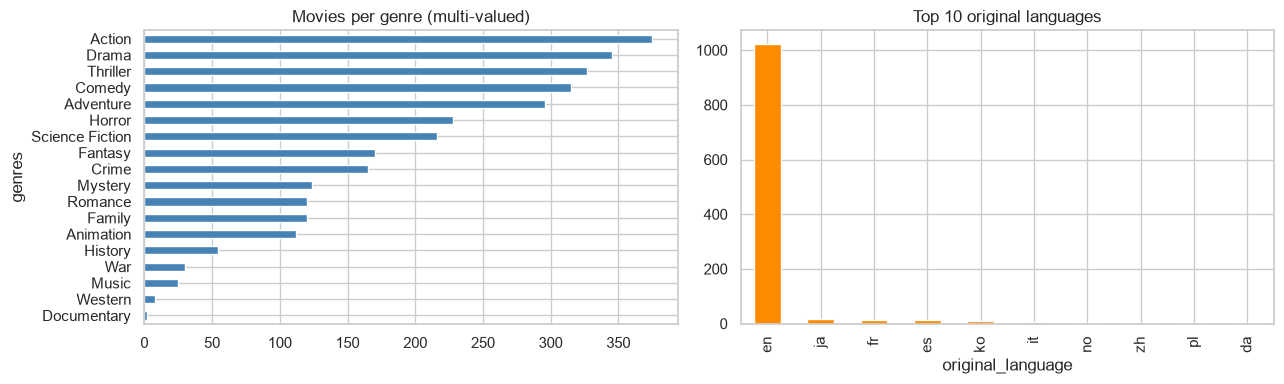

In [11]:
for c in ["status", "original_language", "primary_genre", "primary_country"]:
    vc = df[c].value_counts(dropna=False)
    print(f"--- {c}: {df[c].nunique()} unique ---")
    display(vc.head(10).to_frame("count").assign(percent=lambda x: (x["count"]/len(df)*100).round(1)))

# multi-valued genres: split and count
genre_counts = df["genres"].dropna().str.split("|").explode().value_counts()
print("--- genres (multi-valued, exploded) ---"); display(genre_counts.to_frame("count"))

print("Unique-value counts for high-cardinality fields:")
print(df[["director", "primary_company", "collection_name"]].nunique())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
genre_counts.plot.barh(ax=ax[0], color="steelblue").invert_yaxis(); ax[0].set_title("Movies per genre (multi-valued)")
df["original_language"].value_counts().head(10).plot.bar(ax=ax[1], color="darkorange"); ax[1].set_title("Top 10 original languages")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "p1_categorical_frequencies.png"), dpi=120); plt.show()


**What we did:** we counted the categories in language, genre, country and status, split the genre lists to count every genre, and counted how many different directors, companies and franchises there are. We also plotted the genre and language counts.

**Why:** the number of categories tells us how to encode each column later. Columns with a few categories are easy to one-hot encode. Columns with hundreds need a different approach.

**What we found:** 92.8% of the films are in English. The most common genre is Action (375 films). There are 677 different directors and 465 different main companies, far too many to give each one its own column, so Notebook 2 handles these differently. Every film has the status "Released".

## Step 7: Missing values
TMDB writes **0** when it doesn't know a budget, revenue or runtime. No real film earns exactly $0, so we count those zeros as missing. Films with an unknown **revenue** can't be used for training, because revenue is the thing we're trying to predict.

In [12]:
ZERO_AS_MISSING = ["budget", "revenue", "runtime"]

report = pd.DataFrame({
    "NaN_count": df.isna().sum(),
    "zero_count": [(df[c] == 0).sum() if c in ZERO_AS_MISSING else 0 for c in df.columns],
})
report["missing_total"] = report["NaN_count"] + report["zero_count"]
report["missing_%"] = (report["missing_total"] / len(df) * 100).round(2)
display(report.sort_values("missing_%", ascending=False).query("missing_total > 0"))

df_zero = df.copy()
df_zero[ZERO_AS_MISSING] = df_zero[ZERO_AS_MISSING].replace(0, np.nan)
print("Rows with missing target (revenue):", df_zero["revenue"].isna().sum(),
      f"({df_zero['revenue'].isna().mean()*100:.1f}%)")


,NaN_count,zero_count,missing_total,missing_%
collection_name,708,0,708,64.36
revenue,0,201,201,18.27
budget,0,160,160,14.55
tagline,43,0,43,3.91
production_countries,2,0,2,0.18
top_cast,2,0,2,0.18
primary_country,2,0,2,0.18
primary_company,1,0,1,0.09
production_companies,1,0,1,0.09
imdb_id,1,0,1,0.09


Rows with missing target (revenue): 201 (18.3%)


**What we did:** for every column we counted the real blanks plus the zeros in budget, revenue and runtime, and worked out the percentages. Then we turned those zeros into proper missing values in a copy of the table.

**Why:** if we only counted blanks, it would look as if almost nothing was missing, which would hide the real problem.

**What we found:** revenue is missing for **201 films (18.3%)** and budget for **160 (14.6%)**. No runtimes are missing. `collection_name` (708) and `tagline` (43) have natural gaps. The 201 films with no revenue are removed before modelling in Step 9.

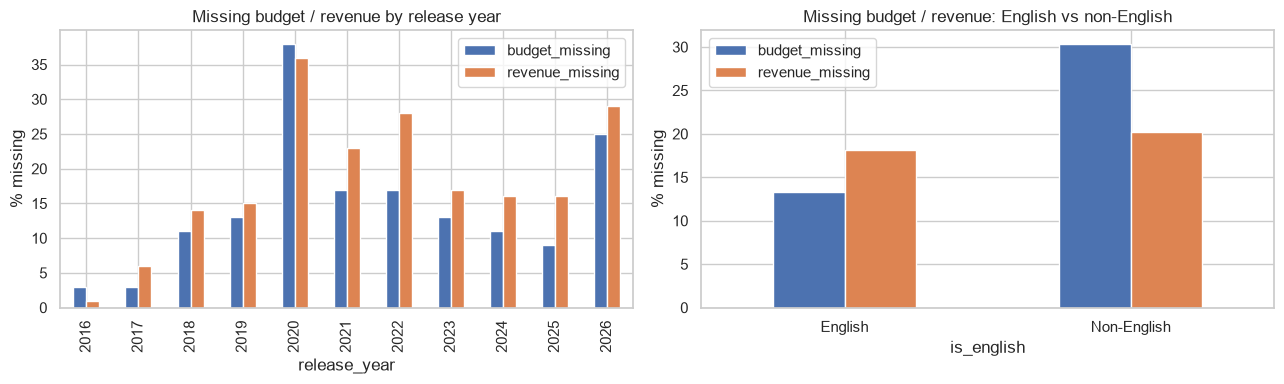

In [13]:
# Is budget/revenue "unknown" random, or linked to era / language? (a quick missingness-pattern check)
tmp = df_zero.assign(budget_missing=df_zero["budget"].isna(), revenue_missing=df_zero["revenue"].isna(),
                     is_english=np.where(df_zero["original_language"] == "en", "English", "Non-English"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(tmp.groupby("release_year")[["budget_missing", "revenue_missing"]].mean() * 100).plot.bar(ax=ax[0])
ax[0].set_ylabel("% missing"); ax[0].set_title("Missing budget / revenue by release year")
(tmp.groupby("is_english")[["budget_missing", "revenue_missing"]].mean() * 100).plot.bar(ax=ax[1], rot=0)
ax[1].set_ylabel("% missing"); ax[1].set_title("Missing budget / revenue: English vs non-English")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "p1_missing_pattern.png"), dpi=120); plt.show()


**What we did:** we compared how often budget and revenue are missing in each release year, and for English versus non-English films.

**Why:** if the missing values follow a pattern, they aren't missing at random, and that could bias our results.

**What we found:** missing revenue peaks in 2020 (36%) and is lowest in 2016 (1%). That fits 2020, when cinemas were closed and many films went straight to streaming. Non-English films are missing their budget far more often (30% against 13% for English films). So the missing data follows a clear pattern, and we mention this in the limitations.

## Step 8: Duplicates
We check three things: rows that are completely identical, the same movie ID appearing twice, and the same title with the same release date under different IDs. We remove duplicates *before* adding the artificial gaps, so no blanked cell is lost when a row is deleted.

In [14]:
n_before = len(df_zero)
exact_dups = df_zero.duplicated().sum()
id_dups = df_zero["id"].duplicated().sum()
title_date_dups = df_zero.duplicated(subset=["title", "release_date"], keep=False).sum()
print(f"Exact duplicate rows      : {exact_dups}")
print(f"Repeated movie IDs        : {id_dups}")
print(f"Same title + release date : {title_date_dups} rows (possible duplicates, manual review)")
if title_date_dups:
    display(df_zero[df_zero.duplicated(subset=["title", "release_date"], keep=False)][["id", "title", "release_date", "vote_count"]].sort_values("title"))

df_final = df_zero.drop_duplicates().drop_duplicates(subset="id", keep="first").reset_index(drop=True)
print(f"\nRows before: {n_before} | removed: {n_before - len(df_final)} | rows after: {len(df_final)}")
assert df_final["id"].is_unique
df_final.to_csv(os.path.join(DATA_DIR, "tmdb_movies_final.csv"), index=False)


Exact duplicate rows      : 0
Repeated movie IDs        : 0
Same title + release date : 0 rows (possible duplicates, manual review)

Rows before: 1100 | removed: 0 | rows after: 1100


**What we did:** we counted exact duplicate rows, repeated IDs and same-title-same-date pairs, removed any duplicates, double-checked that every ID is unique, and saved `tmdb_movies_final.csv`.

**Why:** a movie that appears twice could end up in both the training and the test set, which would make our test scores look better than they really are.

**What we found:** 0 exact duplicates, 0 repeated IDs and 0 same-title pairs, so nothing was removed and 1,100 rows remain. This shows the `seen` set in the collection step did its job.

## Step 9: Removing missing targets and adding ~5% artificial missing values
1. **Model base:** we drop the films with no revenue, since they can't be used for training or testing.
2. **Working copy:** in a separate copy, we blank out about 5% of the values in eight input columns at random (controlled by the seed). The target is never touched.
3. We keep an untouched copy called `truth`, so we can check later how close each fill-in method gets to the real values.

In [15]:
df_model = df_final[df_final["revenue"].notna()].reset_index(drop=True)
print(f"Rows kept for modelling: {len(df_model)} (dropped {len(df_final)-len(df_model)} with missing target)")
df_model.to_csv(os.path.join(DATA_DIR, "tmdb_movies_model_base.csv"), index=False)

MASK_NUM = ["budget", "runtime", "popularity", "vote_count", "vote_average"]
MASK_CAT = ["original_language", "primary_genre", "primary_country"]
MASK_COLS = MASK_NUM + MASK_CAT
MISSING_FRACTION = 0.05

rng = np.random.default_rng(SEED)
work = df_model.copy()
truth = df_model.copy()
mask = pd.DataFrame(False, index=work.index, columns=MASK_COLS)
for c in MASK_COLS:
    available = work.index[work[c].notna()]
    k = min(int(round(MISSING_FRACTION * len(work))), len(available))
    chosen = rng.choice(available, size=k, replace=False)
    work.loc[chosen, c] = np.nan
    mask.loc[chosen, c] = True

assert work["revenue"].notna().all(), "Target must never contain missing values"
before = df_model[MASK_COLS].isna().sum()
after = work[MASK_COLS].isna().sum()
summary = pd.DataFrame({"missing_before": before, "artificially_added": mask.sum(), "missing_after": after,
                        "missing_after_%": (after / len(work) * 100).round(2)})
display(summary)
print(f"Artificially masked cells: {mask.values.sum()} of {len(work)*len(MASK_COLS)} selected cells "
      f"({mask.values.sum()/(len(work)*len(MASK_COLS))*100:.2f}%)")
work.to_csv(os.path.join(DATA_DIR, "tmdb_movies_working_missing.csv"), index=False)


Rows kept for modelling: 899 (dropped 201 with missing target)


,missing_before,artificially_added,missing_after,missing_after_%
budget,32,45,77,8.57
runtime,0,45,45,5.01
popularity,0,45,45,5.01
vote_count,0,45,45,5.01
vote_average,0,45,45,5.01
original_language,0,45,45,5.01
primary_genre,0,45,45,5.01
primary_country,0,45,45,5.01


Artificially masked cells: 360 of 7192 selected cells (5.01%)


**What we did:** we removed the films with missing revenue and saved `tmdb_movies_model_base.csv`. Then, in a copy, we blanked 45 random values in each of eight input columns (five numeric, three categorical) and saved it as `tmdb_movies_working_missing.csv`. A check confirms the revenue column has no gaps.

**Why:** the brief asks for about 5% artificial missing values in the inputs, on a separate copy and never in the target, so we can show how missing data is handled.

**What we found:** **899 films are left for modelling** (201 removed). We blanked 360 cells, which is 5.01% of the selected cells, right on the 5% target. Budget ends up with 77 gaps, because it already had 32 real ones.

## Step 10: Simple imputation (our baseline)
- Numeric columns: fill with the **median**, because it isn't pulled around by a few extreme values
- Categorical columns: fill with the **mode**, the most common value

In [16]:
from scipy.stats import skew
print("Skewness of numeric columns (original, non-missing values):")
print(df_model[MASK_NUM].apply(lambda s: skew(s.dropna())).round(2).to_string())

simple = work.copy()
for c in MASK_NUM:
    simple[c] = simple[c].fillna(simple[c].median())
for c in MASK_CAT:
    simple[c] = simple[c].fillna(simple[c].mode()[0])

cmp = pd.DataFrame({"before_imputation": work[MASK_COLS].isna().sum(), "after_imputation": simple[MASK_COLS].isna().sum()})
display(cmp)


Skewness of numeric columns (original, non-missing values):
budget           2.06
runtime          1.09
popularity      10.71
vote_count       2.35
vote_average    -0.07


,before_imputation,after_imputation
budget,77,0
runtime,45,0
popularity,45,0
vote_count,45,0
vote_average,45,0
original_language,45,0
primary_genre,45,0
primary_country,45,0


**What we did:** we checked how skewed each numeric column is, filled the numeric gaps with the median and the categorical gaps with the most common value, and compared the missing counts before and after.

**Why:** with a long tail of huge values, the mean gets dragged upwards, so the median is the safer single value. For categories, the most common value is the only sensible single choice. This simple approach is the baseline we compare our advanced method against.

**What we found:** skewness is 2.06 for budget, 10.71 for popularity and 2.35 for vote count, all strongly right-skewed, which supports using the median. Every gap is filled. The weakness is that every gap gets the *same* number, which squashes the natural spread and ignores how the columns relate to each other. That's why we try something smarter next.

## Step 11: Advanced Technique #1 — KNN and Iterative imputation

**Why this technique fits our data:** budget, popularity, vote count and runtime are related, because big-budget films usually get more votes and more attention. The median ignores this. Smarter methods can use it:
- **KNN imputation** fills a gap using the 5 most similar films;
- **Iterative imputation** predicts each missing value from the other columns.

**How we set it up:**
- The skewed columns (budget, popularity, vote count) are log-transformed inside the imputer and converted back afterwards, so billion-dollar films don't dominate the distances. Everything is scaled first, because KNN works with distances.
- **Revenue is never used to fill the inputs.** That would leak the answer into the features.
- We score each method on the cells we blanked ourselves, because there we know the true values.
- Fitting and applying are separate functions, so Notebook 2 could fit them on training data only.

In [17]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler

IMP_FEATS = ["budget", "runtime", "popularity", "vote_count", "vote_average",
             "n_genres", "n_companies", "cast_size", "release_year"]      # NOTE: revenue deliberately excluded
LOG_FEATS = ["budget", "popularity", "vote_count"]
ROUND_FEATS = ["n_genres", "n_companies", "cast_size", "release_year"]

def _to_space(df):
    X = df[IMP_FEATS].astype(float).copy()
    for c in LOG_FEATS:
        X[c] = np.log1p(X[c])
    return X

def fit_num_imputer(train_df, method="knn", k=5):
    scaler = StandardScaler().fit(_to_space(train_df))
    imp = (KNNImputer(n_neighbors=k, weights="distance") if method == "knn"
           else IterativeImputer(max_iter=15, random_state=SEED, sample_posterior=False))
    imp.fit(scaler.transform(_to_space(train_df)))
    return scaler, imp

def apply_num_imputer(df, state):
    scaler, imp = state
    Z = imp.transform(scaler.transform(_to_space(df)))
    X = pd.DataFrame(scaler.inverse_transform(Z), columns=IMP_FEATS, index=df.index)
    for c in LOG_FEATS:
        X[c] = np.expm1(X[c]).clip(lower=0)
    X["runtime"] = X["runtime"].clip(lower=1)
    X["vote_average"] = X["vote_average"].clip(0, 10)
    X[ROUND_FEATS] = X[ROUND_FEATS].round()
    out = df.copy()
    for c in MASK_NUM:
        out[c] = df[c].fillna(X[c])
    return out

knn_state = fit_num_imputer(work, "knn")
iter_state = fit_num_imputer(work, "iterative")
imp_knn = apply_num_imputer(work, knn_state)
imp_iter = apply_num_imputer(work, iter_state)
for d in (imp_knn, imp_iter):
    for c in MASK_CAT:                       # categoricals: mode for both
        d[c] = d[c].fillna(work[c].mode()[0])
print("Remaining missing in input columns -> KNN:", int(imp_knn[MASK_COLS].isna().sum().sum()),
      "| Iterative:", int(imp_iter[MASK_COLS].isna().sum().sum()))

Remaining missing in input columns -> KNN: 0 | Iterative: 0


**What we did:** we wrote two functions: one to *fit* an imputer (log → scale → KNN or Iterative) and one to *apply* it (fill the gaps, convert back, and keep values sensible: no negative budgets, ratings between 0 and 10). We ran both methods on the working copy. Categorical gaps are filled with the most common value.

**Why:** splitting "fit" and "apply" keeps the method reusable and leak-free.

**What we found:** both methods filled every gap. The next cell checks how *accurate* those fills are.

Median (baseline)                                  KNN (k=5)                                  Iterative                             
                           MAE          RMSE normalised_MAE           MAE          RMSE normalised_MAE           MAE          RMSE normalised_MAE
column                                                                                                                                           
budget            6.068889e+07  9.615139e+07          0.783  3.997721e+07  7.277679e+07          0.515  2.597540e+07  4.078962e+07          0.335
runtime           1.642200e+01  2.160500e+01          0.821  1.423600e+01  1.788600e+01          0.712  1.285600e+01  1.687500e+01          0.643
popularity        5.688000e+00  9.796000e+00          0.192  4.220000e+00  7.993000e+00          0.142  3.459000e+00  5.899000e+00          0.117
vote_count        2.815700e+03  4.064451e+03          0.605  1.664912e+03  2.411344e+03          0.358  1.589760e+03  2.194953e+03          0.341
vote_average      4.930000e-01  6.390000e-01          0.758  4.660000e-01  5.730000e-01          0.717  3.850000e-01  4.950000e-01          0.593

Normalised MAE (MAE / std of true values) - lower is better:


,Median (baseline),KNN (k=5),Iterative,best
column,,,,
budget,0.783,0.515,0.335,Iterative
runtime,0.821,0.712,0.643,Iterative
popularity,0.192,0.142,0.117,Iterative
vote_count,0.605,0.358,0.341,Iterative
vote_average,0.758,0.717,0.593,Iterative


Mean normalised MAE:
 Median (baseline)    0.632
KNN (k=5)            0.489
Iterative            0.406

Mode-imputation accuracy on masked categorical cells: {'original_language': np.float64(0.911), 'primary_genre': np.float64(0.2), 'primary_country': np.float64(0.644)}


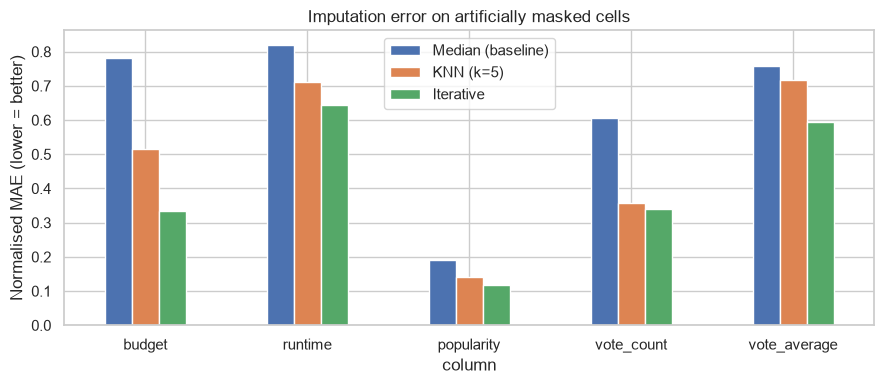

In [18]:
def imputation_error(imputed):
    rows = []
    for c in MASK_NUM:
        m = mask[c]
        err = imputed.loc[m, c] - truth.loc[m, c]
        rows.append({"column": c, "MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean()),
                     "normalised_MAE": err.abs().mean() / truth[c].std()})
    return pd.DataFrame(rows).set_index("column")

err_tbl = pd.concat({"Median (baseline)": imputation_error(simple),
                     "KNN (k=5)": imputation_error(imp_knn),
                     "Iterative": imputation_error(imp_iter)}, axis=1)
display(err_tbl.round(3))

norm = pd.DataFrame({m: err_tbl[m]["normalised_MAE"] for m in ["Median (baseline)", "KNN (k=5)", "Iterative"]})
print("Normalised MAE (MAE / std of true values) - lower is better:")
display(norm.round(3).assign(best=norm.idxmin(axis=1)))
print("Mean normalised MAE:\n", norm.mean().round(3).to_string())

# categorical: accuracy of mode-fill on the masked cells
acc = {c: (simple.loc[mask[c], c] == truth.loc[mask[c], c]).mean() for c in MASK_CAT}
print("\nMode-imputation accuracy on masked categorical cells:", {k: round(v, 3) for k, v in acc.items()})

norm.plot.bar(figsize=(9, 4), rot=0); plt.ylabel("Normalised MAE (lower = better)")
plt.title("Imputation error on artificially masked cells"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "p1_imputation_error.png"), dpi=120); plt.show()


**What we did:** on the cells we blanked ourselves, we compared the median, KNN and Iterative methods against the true values. For each column we measured the average error (MAE), RMSE, and a "normalised" error (MAE divided by the column's spread), so that dollars and ratings can be compared fairly.

**Why:** this is the before-and-after evidence for our advanced technique. It shows whether the smarter methods are actually better.

**What we found:** the average normalised error is **0.632 for the median, 0.489 for KNN and 0.406 for Iterative**. So KNN cuts the error by about 23% and **Iterative by about 36%**. Iterative was the most accurate for all five columns, with budget improving the most. For the categories, filling with the most common value was right 91% of the time for language (most films are in English) but only 20% for genre, because no single genre dominates.

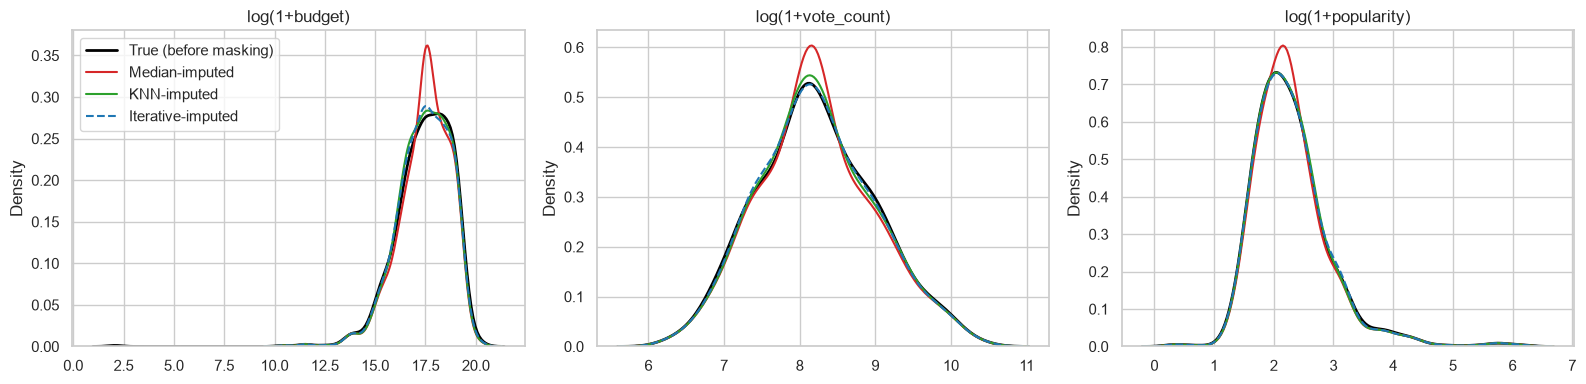

,true_std,median_std,knn_std,iterative_std
budget,77551425.01,73886700.43,75119964.48,76267911.09
runtime,20.00,19.41,19.59,19.59
popularity,29.65,29.59,29.59,29.61
vote_count,4656.75,4594.80,4624.40,4624.26
vote_average,0.65,0.63,0.64,0.64


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, col in zip(axes, ["budget", "vote_count", "popularity"]):
    sns.kdeplot(np.log1p(truth[col].dropna()), ax=ax, label="True (before masking)", color="black", lw=2)
    sns.kdeplot(np.log1p(simple[col]), ax=ax, label="Median-imputed", color="tab:red")
    sns.kdeplot(np.log1p(imp_knn[col]), ax=ax, label="KNN-imputed", color="tab:green")
    sns.kdeplot(np.log1p(imp_iter[col]), ax=ax, label="Iterative-imputed", color="tab:blue", ls="--")
    ax.set_title(f"log(1+{col})"); ax.set_xlabel("")
axes[0].legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "p1_imputation_distributions.png"), dpi=120); plt.show()

std_tbl = pd.DataFrame({"true_std": truth[MASK_NUM].std(), "median_std": simple[MASK_NUM].std(), "knn_std": imp_knn[MASK_NUM].std(), "iterative_std": imp_iter[MASK_NUM].std()})
display(std_tbl.round(2))


**What we did:** we plotted the distributions of budget, vote count and popularity (on a log scale) for the true data, the median-filled data, the KNN-filled data and the Iterative-filled data, and compared their standard deviations.

**Why:** filling every gap with the same number creates a spike in the distribution and shrinks the spread. This shows the effect *on the data itself*.

**What we found:** for 5 of 5 columns, KNN and Iterative keep the spread closer to the true value than the median does. Budget shows it most clearly: the true spread is about $77.6 million, while the median fill shrinks it to about $73.9 million and Iterative keeps about $76.3 million. The smarter methods follow the true curve without the artificial spike.

## Step 12: Saving the cleaned dataset
We keep whichever method had the lower error in Step 11. KNN is the default, but Iterative is used if it's clearly better (by more than 0.01). In our case Iterative won.

In [20]:
CHOSEN = "Iterative" if norm.mean()["Iterative"] < norm.mean()["KNN (k=5)"] - 0.01 else "KNN (k=5)"   # KNN unless Iterative is clearly better
final_imputed = (imp_iter if CHOSEN == "Iterative" else imp_knn).copy()
print("Imputation used for the cleaned dataset:", CHOSEN)
final_imputed.to_csv(os.path.join(DATA_DIR, "tmdb_movies_imputed.csv"), index=False)

manifest = {p: sha256_file(os.path.join(DATA_DIR, p)) for p in
            ["tmdb_movies_raw.csv", "raw_responses.jsonl", "movie_ids.csv", "tmdb_movies_final.csv",
             "tmdb_movies_model_base.csv", "tmdb_movies_working_missing.csv", "tmdb_movies_imputed.csv"]
            if os.path.exists(os.path.join(DATA_DIR, p))}
ids_fingerprint = hashlib.sha256(",".join(map(str, sorted(pd.read_csv(os.path.join(DATA_DIR, "movie_ids.csv"))["id"]))).encode()).hexdigest()
manifest["movie_ids_list"] = ids_fingerprint
with open(os.path.join(DATA_DIR, "sha256_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

pipeline = pd.DataFrame([
    ("Raw collected rows", len(df_raw)),
    ("After duplicate removal (tmdb_movies_final.csv)", len(df_final)),
    ("Rows with missing target removed", len(df_final) - len(df_model)),
    ("Rows available for modelling", len(df_model)),
    ("Artificially masked cells", int(mask.values.sum())),
    ("Missing input cells after imputation", int(final_imputed[MASK_COLS].isna().sum().sum())),
], columns=["Stage", "Value"])
display(pipeline)
print("Files in data/:", sorted(os.listdir(DATA_DIR)))
print("\nSHA-256 manifest updated.")


Imputation used for the cleaned dataset: Iterative


,Stage,Value
0,Raw collected rows,1100
1,After duplicate removal (tmdb_movies_final.csv),1100
2,Rows with missing target removed,201
3,Rows available for modelling,899
4,Artificially masked cells,360
5,Missing input cells after imputation,0


Files in data/: ['collection_log.json', 'movie_ids.csv', 'raw_json', 'raw_responses.jsonl', 'sha256_manifest.json', 'tmdb_movies_final.csv', 'tmdb_movies_imputed.csv', 'tmdb_movies_model_base.csv', 'tmdb_movies_raw.csv', 'tmdb_movies_working_missing.csv']

SHA-256 manifest updated.


**What we did:** we saved the cleaned (imputed) copy, updated the fingerprints for every data file, and printed a summary of how many rows were left after each stage.

**Why:** the brief asks for the raw dataset, the final CSV, the working copy with missing values, and a cleaned dataset. The updated fingerprints record exactly which versions we produced.

**What we found:** the cleaned file uses **Iterative** imputation and has no gaps left. We go from 1,100 raw films to **899** usable ones, mainly because 201 films have no reported revenue.

### Limitations of the data
1. Sorting by vote count favours popular films, so this isn't a random sample of all movies.
2. Budget and revenue are entered by TMDB users and are often missing or rough.
3. Popularity is a snapshot of the download day and changes every day.
4. 2026 isn't over yet, so many 2026 films are still earning.
5. Our artificial gaps are random, which makes them easier to fill than the real gaps, which follow patterns (Step 7).